# Persona Atlas: personas from telco behaviour

Can we tell a **college student** from a **blue-collar worker** or a **mom with kids** using only what a mobile network sees?
No names, no surveys, no app SDK: just the **domains** a line reaches, **when**, **which cell area**, and **how much data** it uses.

This notebook rebuilds the method on **simulated** Jakarta data:

1. Simulate subscribers and their network events
2. Train **Word2Vec** on daily token sequences
3. Build one vector per subscriber and cluster into personas
4. Name the clusters and read their profiles
5. Grow an audience with a **look-alike** model and measure the precision/recall tradeoff
6. Export a 3D layout for the interactive demo in `web/`

> The original system ran at Eureka AI (2021–2024) on 80M+ subscribers. All data here is synthetic, and the code is a clean reimplementation.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from persona_atlas.personas import AREAS, CATEGORIES, all_personas, hourly_curve
from persona_atlas.simulate import simulate
from persona_atlas import model as m
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

## 1. Simulate the network
20,000 subscribers × 5 days. Each person gets their own twist on their persona's habits, and 15% of events are pure noise.

In [2]:
people, sentences, owner = simulate(n=20000, days=5)
print(f'{len(people):,} subscribers · {len(sentences):,} day-sentences · {sum(map(len, sentences)):,} tokens')
people.head()

20,000 subscribers · 100,000 day-sentences · 5,519,626 tokens


,persona,persona_name,named,home,gb_month,night_share,mobility_km
0,gamer,Mobile gamer,True,jakarta_utara,28.844820,0.518863,4.708882
1,p20,Persona 20,False,depok,24.089056,0.397836,11.672915
2,affl,Affluent family,True,jakarta_selatan,56.336478,0.130888,14.532868
3,wc,White collar,True,bekasi,31.450680,0.163294,9.966347
4,bc,Blue collar,True,depok,9.855399,0.147400,4.809288


What one day of one college student looks like to the network:

In [3]:
i = people.index[people.persona == 'col'][0]
print(' '.join(sentences[np.flatnonzero(owner == i)[0]][:40]), '...')

ride_delivery-05.example t0 learning-01.example t0 ride_delivery-00.example t0 cell_depok ewallet_bank-00.example t2 cell_jakarta_selatan ride_delivery-05.example t3 ride_delivery-05.example t3 ride_delivery-01.example t3 ecommerce-04.example t4 ecommerce-03.example t4 cell_jakarta_selatan ecommerce-02.example t4 cell_jakarta_selatan video-04.example t4 cell_jakarta_selatan games-05.example t5 ecommerce-05.example t5 work_news-02.example t5 cell_jakarta_selatan video-00.example t6 work_news-02.example t6 ride_delivery-03.example t6 ...


## 2. Word2Vec on behaviour
Treat each day as a sentence. Tokens that occur in the same contexts (same people, same times, same places) end up close together.

In [4]:
w2v = m.train_word2vec(sentences)
for tok in ['learning-00.example', 'gig_jobs-00.example', 't0', 'cell_bekasi']:
    print(f'{tok:22s} →', ', '.join(t for t, _ in w2v.wv.most_similar(tok, topn=4)))

learning-00.example    → learning-01.example, learning-04.example, learning-02.example, learning-03.example
gig_jobs-00.example    → gig_jobs-04.example, gig_jobs-02.example, gig_jobs-05.example, gig_jobs-01.example
t0                     → t1, t2, t3, games-04.example
cell_bekasi            → cell_jakarta_pusat, cell_jakarta_selatan, video-03.example, video-01.example


## 3. Subscriber vectors and clusters
Mean token vector + scaled usage features (GB/month, night share, mobility radius), then K-means with k = 30, the size of the production catalogue.

In [5]:
X = m.subscriber_vectors(w2v, sentences, owner, people)
labels, centers = m.cluster(X, k=30)
people['cluster'] = labels
ct = pd.crosstab(people.cluster, people.persona_name)
purity = ct.max(axis=1).sum() / len(people)
print(f'Adjusted Rand index vs. true persona: {adjusted_rand_score(people.persona, labels):.2f}')
print(f'Cluster purity: {purity:.0%}')

Adjusted Rand index vs. true persona: 0.44
Cluster purity: 67%


Purity is well below 100% on purpose: the simulation gives people overlapping habits, like real people. Persona assignment is a probability, not a fact.

## 4. Naming clusters
An analyst names each cluster from its profile. Here we cheat a little and use the simulated truth: a cluster takes the name of its majority persona if that persona is at least 45% of it.

In [6]:
top = ct.idxmax(axis=1); top_share = ct.max(axis=1) / ct.sum(axis=1)
named = {p.name for p in all_personas() if p.named}
cluster_name = {k: (top[k] if top_share[k] >= .45 and top[k] in named else 'Other') for k in ct.index}
people['label'] = people.cluster.map(cluster_name)
summary = people.groupby('label').agg(share=('cluster', 'size'), gb=('gb_month', 'median'),
                                      night=('night_share', 'median'), km=('mobility_km', 'median'))
summary['share'] = (summary.share / len(people)).map('{:.1%}'.format)
summary.round(2).sort_values('gb', ascending=False)

,share,gb,night,km
label,,,,
Mobile gamer,4.8%,38.88,0.48,2.99
White collar,12.8%,28.99,0.13,13.76
College student,8.5%,21.86,0.40,10.31
Bodetabek commuter,6.7%,18.00,0.10,34.01
Mom with kids,3.8%,17.70,0.14,5.40
Other,26.5%,16.39,0.20,7.11
High school student,5.2%,15.37,0.34,3.69
Night-shift worker,4.4%,12.79,0.62,9.70
Informal worker,13.4%,11.43,0.28,22.62


## 4b. Supervised where labels exist
Clustering is the default, but some personas have labels. **White collar** is the clearest case: a telco knows which
lines sit on a **corporate-paid plan**, and a small occupation survey covers a few percent of subscribers. With labels,
a supervised model on the same behaviour vectors beats "whichever cluster you fell into", because white-collar people
who live unusual routines no longer get lost in other clusters.

The final catalogue is hybrid: supervised personas first, clusters for the rest.

In [7]:
rng = np.random.default_rng(11)
wc = (people.persona == 'wc').to_numpy(bool)
corporate = (rng.random(len(people)) < np.where(wc, .35, .03)).astype(float)[:, None]   # corporate-paid plan: strong but partial proxy
wc_pred, wc_prob, wc_rep = m.supervised_persona(X, wc, (people.label == 'White collar').to_numpy(bool), extra=corporate)
print(f"labelled subscribers used: {wc_rep['labelled']:,} ({wc_rep['labelled'] / len(people):.0%})")
pd.DataFrame({k: wc_rep[k] for k in ('clustering', 'supervised')}).T.round(2)

labelled subscribers used: 585 (3%)


,precision,recall
clustering,0.67,0.87
supervised,0.87,0.96


In [8]:
people['method'] = 'cluster'
people.loc[wc_pred, 'label'] = 'White collar'; people.loc[wc_pred, 'method'] = 'supervised'
people.loc[(people.label == 'White collar') & ~wc_pred, 'label'] = 'Other'
people.label.value_counts(normalize=True).round(3).head(12)

label
Other                  0.293
Informal worker        0.133
White collar           0.109
Blue collar            0.106
College student        0.083
Bodetabek commuter     0.063
High school student    0.052
Mobile gamer           0.048
Night-shift worker     0.044
Mom with kids          0.036
Retiree                0.032
Name: proportion, dtype: float64

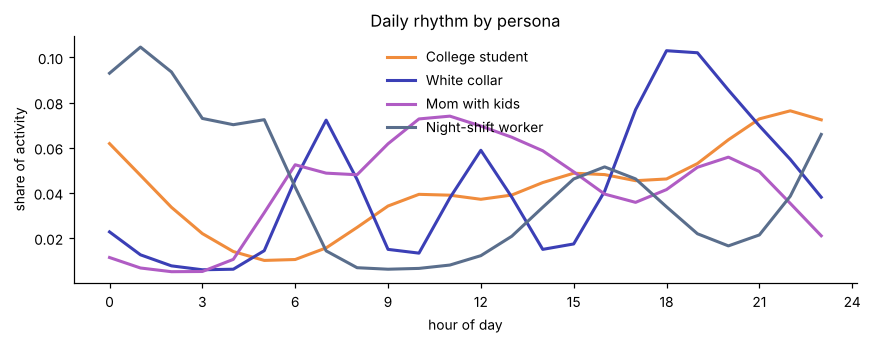

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for p in all_personas():
    if p.name in ('College student', 'White collar', 'Night-shift worker', 'Mom with kids'):
        ax.plot(hourly_curve(p), label=p.name, color=np.array(p.color) / 255, lw=2)
ax.set(xlabel='hour of day', ylabel='share of activity', xticks=range(0, 25, 3), title='Daily rhythm by persona')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig('../docs/daily-rhythm.png'); plt.show()

## 5. Look-alike audiences
A client brings a small **seed list** (2% of the real college students, for example from a survey). Everyone else is ranked by cosine similarity to the seed centre. A bigger audience means more reach and lower precision.

,audience,precision,recall,x_true_size
0,317,0.98,0.25,0.24
1,635,0.94,0.47,0.49
2,953,0.90,0.67,0.74
3,1271,0.82,0.82,0.98
4,1906,0.62,0.93,1.47
5,2542,0.48,0.96,1.96
6,3813,0.33,0.99,2.94


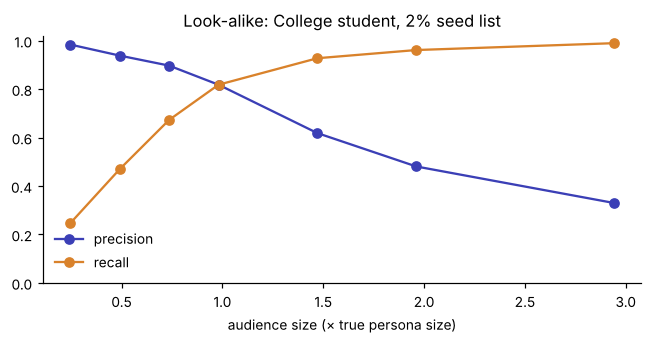

In [10]:
truth = (people.persona == 'col').values
curve, score = m.lookalike_curve(X, truth, seed_frac=.02)
lc = pd.DataFrame(curve); lc['x_true_size'] = lc.audience / (truth.sum())
display(lc.round(2))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(lc.x_true_size, lc.precision, 'o-', label='precision', color='#3b3fb6')
ax.plot(lc.x_true_size, lc.recall, 'o-', label='recall', color='#d9822b')
ax.set(xlabel='audience size (× true persona size)', ylim=(0, 1.02), title='Look-alike: College student, 2% seed list')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig('../docs/lookalike.png'); plt.show()

## 6. 3D layout for the web demo
Cluster centres are placed with MDS, so similar personas sit close together. Each subscriber is then placed around its centre by local PCA. The demo in `web/` reads `web/data/points.json`.

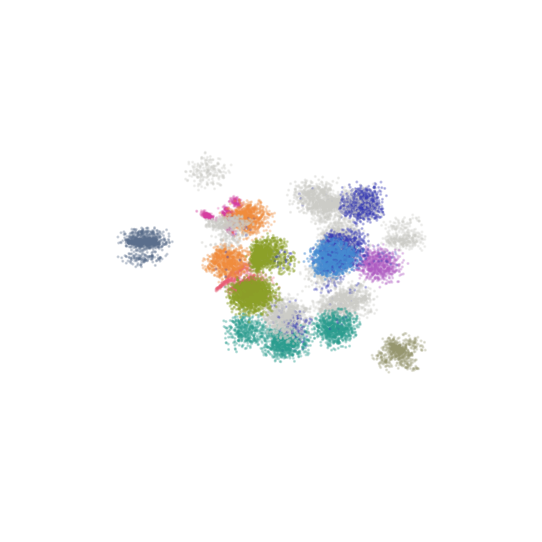

In [11]:
pos = m.layout_3d(X, labels, centers)
order = [p for p in all_personas() if p.named]
pidx = np.array([next((j for j, p in enumerate(order) if p.name == l), -1) for l in people.label])
aidx = people.home.map({a: j for j, a in enumerate(AREAS)}).values
meta = dict(n=len(people), personas=[p.name for p in order], areas=AREAS, supervised=['White collar'], wc=wc_rep,
            note='Simulated data. Coordinates ×10. persona = -1 means other clusters.')
m.export_web('../web/data/points.json', pos, pidx, aidx, meta)

fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
col = np.array([np.array(order[j].color) / 255 if j >= 0 else (.8, .8, .78) for j in pidx])
ax.scatter(*pos.T, c=col, s=1, alpha=.6); ax.set_axis_off(); ax.view_init(18, -30)
plt.tight_layout(); plt.savefig('../docs/atlas-3d.png'); plt.show()

## Takeaways
- Behaviour alone separates personas well enough to sell audiences, but assignment is probabilistic, so report sizes with that in mind.
- Look-alike reach is a dial. Doubling the audience past the true persona size roughly halves precision.
- In production: about 80M subscribers, PySpark for token building, Word2Vec on Spark, MLflow for runs, and 30+ personas reused across clients.